
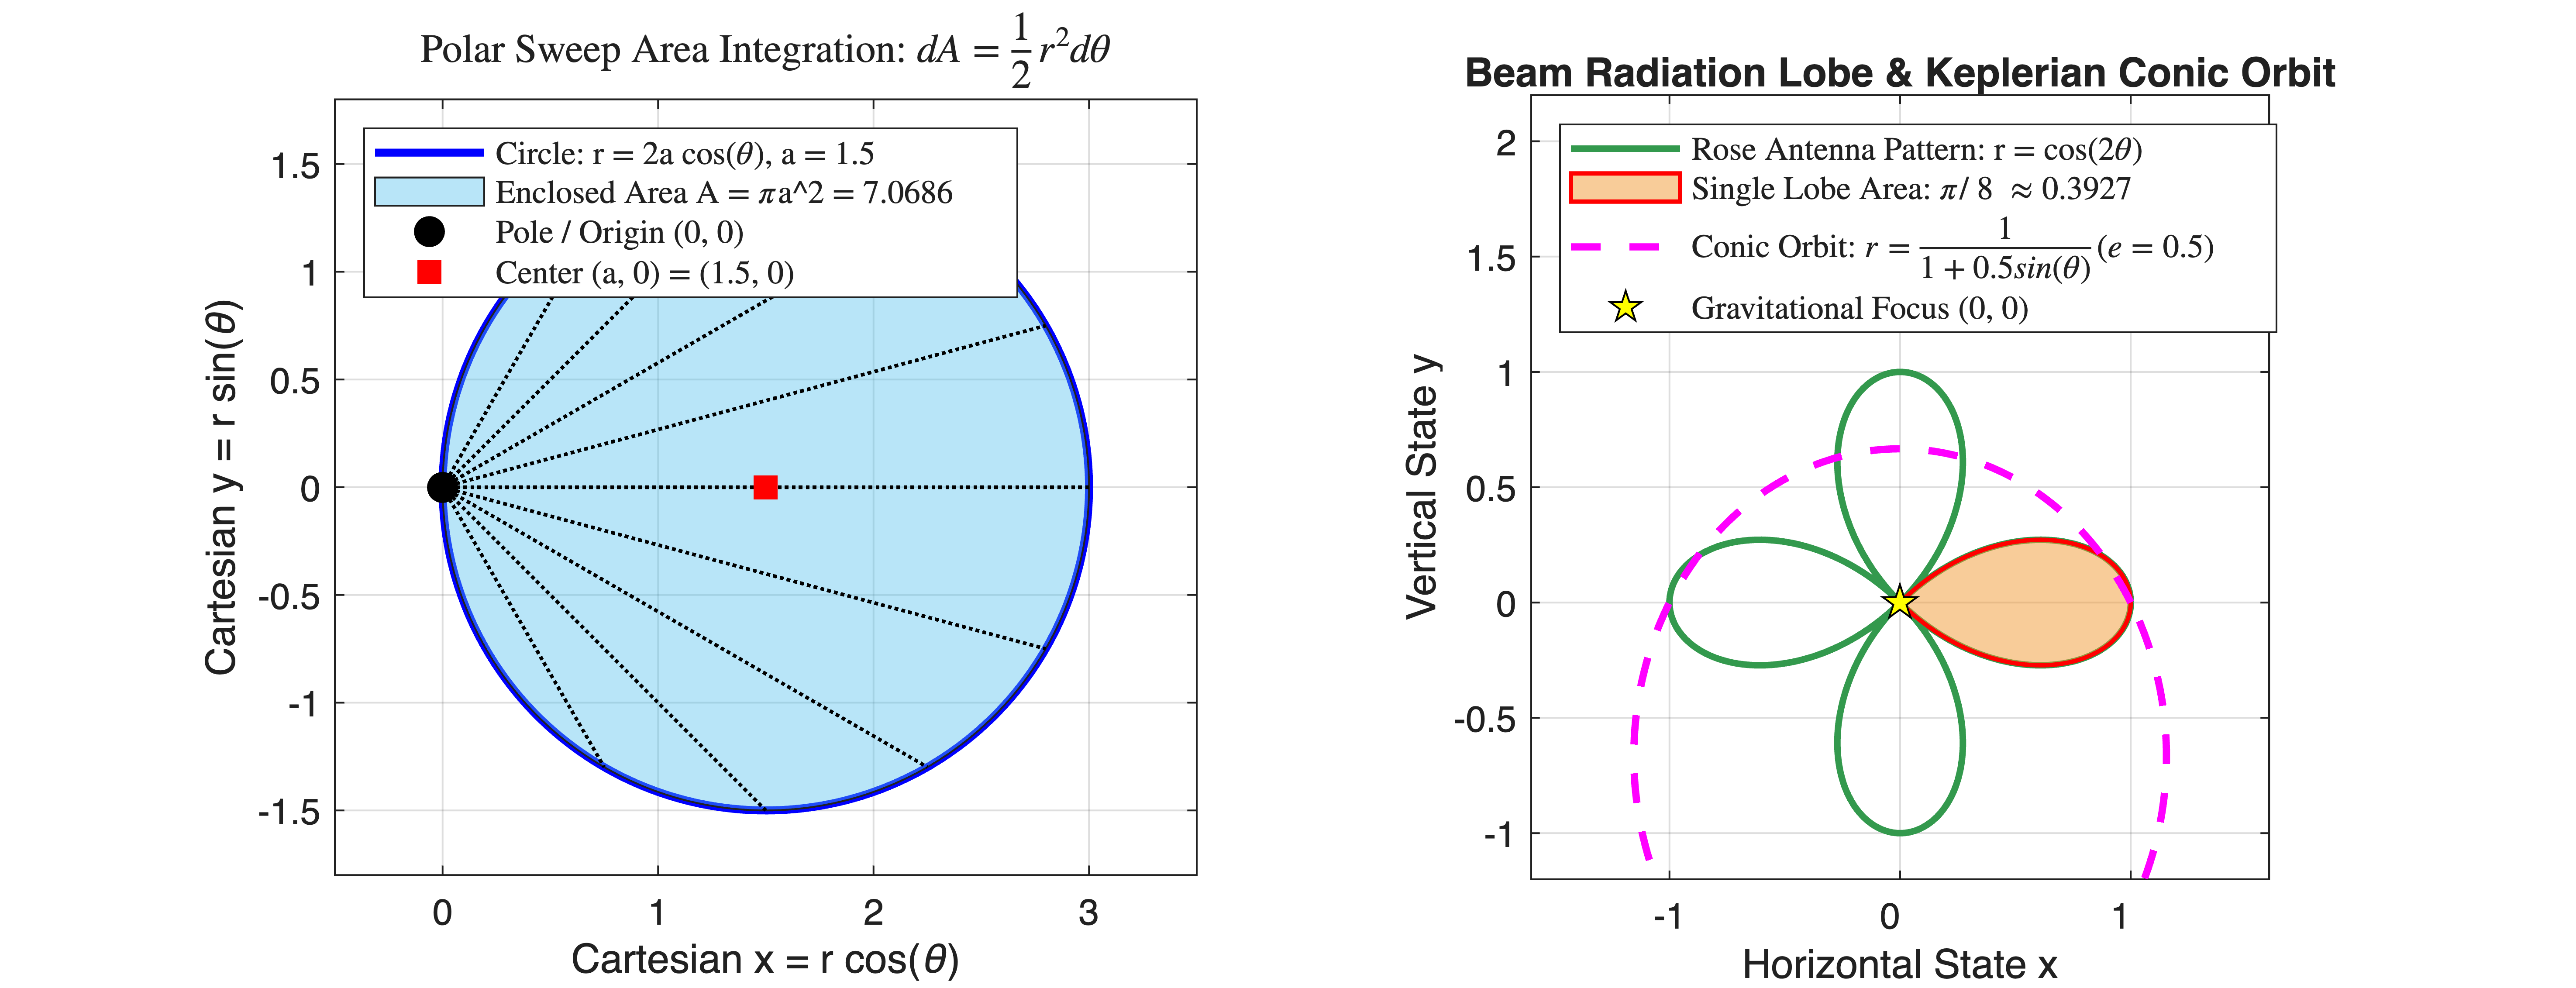

In [1]:
%% MIT 18.01 Lecture 32: Polar Coordinates, Conic Orbits & Area Slicing Simulation
% Mathematical Tool Application: Used for radar/LiDAR point cloud coordinate transformation,
% orbital mechanics Keplerian areal velocity calculations, and antenna radiation beam pattern integration.


clear; clc; close all;


%% Part 1: Offset Circle Swept Slicing (r = 2*a*cos(theta), a = 1.5)
% Cartesian form: (x - a)^2 + y^2 = a^2. Enclosed Area = pi * a^2
a_radius = 1.5;
exact_circle_area = pi * (a_radius^2);


% Angular span tracing circle exactly once: theta in [-pi/2, pi/2]
theta_circle = linspace(-pi/2, pi/2, 300);
r_circle = 2.0 * a_radius * cos(theta_circle);


x_circle = r_circle .* cos(theta_circle);
y_circle = r_circle .* sin(theta_circle);


figure('Color', 'w', 'Position', [100, 100, 1250, 480]);


subplot(1, 2, 1);
% Plot Polar Contour mapped onto Cartesian Axes
plot(x_circle, y_circle, 'b-', 'LineWidth', 2.2, ...
    'DisplayName', sprintf('Circle: r = 2a cos(\\theta), a = %.1f', a_radius)); hold on;


% Fill integrated polar area
fill(x_circle, y_circle, [0.3, 0.75, 0.93], 'FaceAlpha', 0.4, ...
    'DisplayName', sprintf('Enclosed Area A = \\pi a^2 = %.4f', exact_circle_area));


% Draw polar ray sweeps to illustrate dA = 0.5 * r^2 dtheta
ray_angles = linspace(-pi/3, pi/3, 9);
for i = 1:length(ray_angles)
    th_ray = ray_angles(i);
    r_ray = 2.0 * a_radius * cos(th_ray);
    plot([0, r_ray * cos(th_ray)], [0, r_ray * sin(th_ray)], 'k:', 'LineWidth', 1.0, 'HandleVisibility', 'off');
end


% Mark Center and Origin
plot(0, 0, 'ko', 'MarkerSize', 8, 'MarkerFaceColor', 'k', 'DisplayName', 'Pole / Origin (0, 0)');
plot(a_radius, 0, 'rs', 'MarkerSize', 8, 'MarkerFaceColor', 'r', 'DisplayName', sprintf('Center (a, 0) = (%.1f, 0)', a_radius));


axis equal; grid on;
xlim([-0.5, 3.5]); ylim([-1.8, 1.8]);
xlabel('Cartesian x = r cos(\theta)');
ylabel('Cartesian y = r sin(\theta)');
title('Polar Sweep Area Integration: $dA = \frac{1}{2} r^2 d\theta$','Interpreter','latex');
legend('Location', 'northwest','Interpreter','latex');


%% Part 2: Conic Orbit (Example 7) & Four-Petal Antenna Pattern (Example 8)
subplot(1, 2, 2);


% 1. Four-Petal Rose: r = cos(2*theta)
theta_rose = linspace(0, 2*pi, 600);
r_rose = cos(2.0 * theta_rose);
x_rose = r_rose .* cos(theta_rose);
y_rose = r_rose .* sin(theta_rose);


plot(x_rose, y_rose, 'Color', [0.2, 0.6, 0.3], 'LineWidth', 1.8, ...
    'DisplayName', 'Rose Antenna Pattern: r = cos(2\theta)'); hold on;


% Highlight First Petal Area: theta in [-pi/4, pi/4] where r >= 0
th_petal1 = linspace(-pi/4, pi/4, 200);
r_petal1 = cos(2.0 * th_petal1);
x_p1 = r_petal1 .* cos(th_petal1);
y_p1 = r_petal1 .* sin(th_petal1);


% Single Petal Analytic Area: \int_{-pi/4}^{pi/4} 0.5 * cos^2(2*theta) dtheta = pi / 8
petal_area_analytic = pi / 8.0;
fill([0, x_p1, 0], [0, y_p1, 0], [0.95, 0.6, 0.2], 'FaceAlpha', 0.5, ...
    'EdgeColor', 'r', 'LineWidth', 1.2, ...
    'DisplayName', sprintf('Single Lobe Area: \\pi / 8 \\approx %.4f', petal_area_analytic));


% 2. Keplerian Elliptic Orbit: r = 1 / (1 + 0.5*sin(theta))
theta_orbit = linspace(0, 2*pi, 400);
r_orbit = 1.0 ./ (1.0 + 0.5 * sin(theta_orbit));
x_orbit = r_orbit .* cos(theta_orbit);
y_orbit = r_orbit .* sin(theta_orbit);


plot(x_orbit, y_orbit, 'm--', 'LineWidth', 2.0, ...
    'DisplayName', 'Conic Orbit: $r = \frac{1}{1 + 0.5 sin(\theta)} (e = 0.5)$');
plot(0, 0, 'kp', 'MarkerSize', 10, 'MarkerFaceColor', 'y', 'DisplayName', 'Gravitational Focus (0, 0)');


axis equal; grid on;
xlim([-1.6, 1.6]); ylim([-1.2, 2.2]);
xlabel('Horizontal State x');
ylabel('Vertical State y');
title('Beam Radiation Lobe & Keplerian Conic Orbit');
legend('Location', 'northwest','Interpreter','latex');

In [2]:


%% Numerical Quadrature Verification for One Petal of Rose Curve
f_polar_integrand = @(th) 0.5 * (cos(2.0 * th).^2);
num_petal_area = integral(f_polar_integrand, -pi/4, pi/4, 'RelTol', 1e-12, 'AbsTol', 1e-14);
fprintf('Petal Area Verification: Numerical = %.10f | Exact (\\pi/8) = %.10f (Diff: %.2e)\n', ...
    num_petal_area, petal_area_analytic, abs(num_petal_area - petal_area_analytic));

Petal Area Verification: Numerical = 0.3926990817 | Exact (\pi/8) = 0.3926990817 (Diff: 5.55e-17)